# 01 — Data overview

A first look at the processed NHANES data before feature engineering and modelling:
who is in the cohort, how common suicidal ideation is, how many cases the depression
screen misses, which routinely recorded factors go with it, and where data are missing.

**Before running:** `python scripts/fetch_data.py` and `python scripts/build_dataset.py`
(see the README). Every number here is an aggregate.

**Weights.** Prevalences marked *weighted* use the NHANES examination weights
(`weight_mec`), so they describe the US adult population. They are point estimates;
design-based confidence intervals come in step 3. Risk ratios are crude and unweighted.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter

from hidden_risk.config import DATA_PROCESSED, REPORT_TABLES
from hidden_risk.plotting import (AXIS, BLUE, INK_2, MUTED, NEUTRAL_FILL, ORANGE,
                                  SEQUENTIAL, save, use_style)

use_style()
pd.set_option("display.precision", 2)

df = pd.read_parquet(DATA_PROCESSED / "nhanes_2005_2018.parquet")
trend = pd.read_parquet(DATA_PROCESSED / "nhanes_2021_2023_phq9.parquet")


def weighted_prevalence(data: pd.DataFrame, by, outcome: str = "si") -> pd.Series:
    """Survey-weighted % of `outcome` per group."""
    w = data["weight_mec"]
    num = (data[outcome] * w).groupby(by, observed=True).sum()
    return 100 * num / w.groupby(by, observed=True).sum()


print(f"{len(df):,} adults, {int(df.si.sum()):,} with suicidal ideation "
      f"({df.si.mean():.1%} unweighted, "
      f"{np.average(df.si, weights=df.weight_mec):.1%} weighted)")

36,259 adults, 1,366 with suicidal ideation (3.8% unweighted, 3.3% weighted)


## 1. The cohort per survey cycle

Adults (18+) with a complete PHQ-9. `si` = PHQ-9 item 9 answered *several days* or more;
`si_strict` = *more than half the days* or more. Cycles 2005–2014 are the training set,
2015–2018 the test set.

In [2]:
pd.read_csv(REPORT_TABLES / "cohort_by_cycle.csv").fillna({"split": ""})

,cycle,split,adults,si_cases,si_pct,si_strict_cases,si_with_phq8_below_10_pct,si_with_phq9_below_10_pct
0,2005-2006,train,4799,162,3.38,43,48.8,43.2
1,2007-2008,train,5415,246,4.54,71,41.9,33.7
2,2009-2010,train,5546,202,3.64,59,47.0,36.6
3,2011-2012,train,4925,190,3.86,68,40.5,33.2
4,2013-2014,train,5372,183,3.41,62,39.3,29.5
5,2015-2016,test,5134,192,3.74,66,39.1,33.3
6,2017-2018,test,5068,191,3.77,55,40.8,33.5
7,total,,36259,1366,3.77,424,42.4,34.6


## 2. Is suicidal ideation stable over time?

Sub-question 2 tests whether a model trained on older waves still works on newer ones.
That is easier if the outcome itself does not drift.

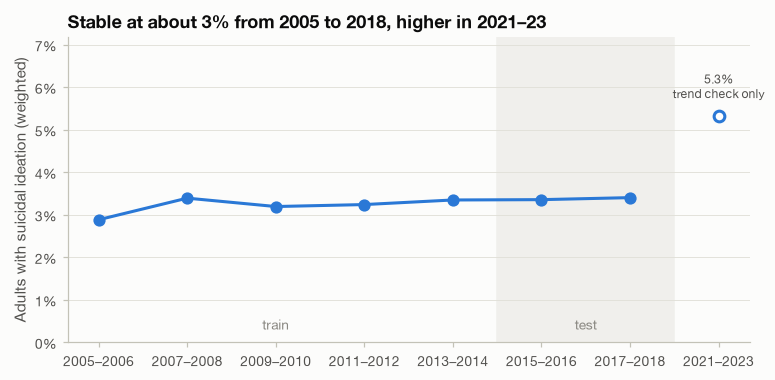

cycle,2005-2006,2007-2008,2009-2010,2011-2012,2013-2014,2015-2016,2017-2018,2021-2023
weighted_si_%,2.88,3.39,3.19,3.24,3.35,3.35,3.4,5.31


In [3]:
by_cycle = weighted_prevalence(df, df["cycle"])
trend_value = np.average(trend.si, weights=trend.weight_mec) * 100

labels = list(by_cycle.index) + ["2021-2023"]
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(4.5, 6.5, color=NEUTRAL_FILL, zorder=0)
ax.text(2, 0.3, "train", ha="center", color=MUTED, fontsize=9)
ax.text(5.5, 0.3, "test", ha="center", color=MUTED, fontsize=9)
ax.plot(x[:7], by_cycle.values, marker="o", color=BLUE)
ax.plot(x[7], trend_value, marker="o", markerfacecolor="white", markeredgewidth=2, color=BLUE)
ax.annotate(f"{trend_value:.1f}%\ntrend check only", (x[7], trend_value), textcoords="offset points",
            xytext=(0, 12), ha="center", fontsize=8, color=INK_2)
ax.set_xticks(x, [l.replace("-", "–") for l in labels])
ax.set_ylim(0, max(by_cycle.max(), trend_value) * 1.35)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Adults with suicidal ideation (weighted)")
ax.set_title("Stable at about 3% from 2005 to 2018, higher in 2021–23")
save(fig, "01_si_prevalence_by_cycle")
plt.show()

by_cycle.rename("weighted_si_%").to_frame().T.assign(**{"2021-2023": trend_value})

## 3. How many cases does the depression screen miss?

A PHQ score of 10 or more is a positive depression screen. The research question uses the
PHQ-9 screen (all nine items). Item 9 is the outcome itself, so the chart shows the score on
the **other eight items** (PHQ-8) of every adult **with** suicidal ideation: what the screen
knows about them apart from the ideation. The printed line below gives both screens.

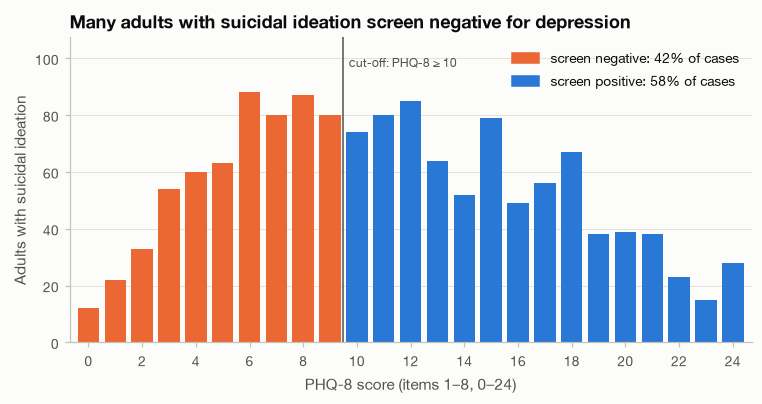

Cases with PHQ-8 < 10: 579 of 1,366 (42.4% unweighted, 43.7% weighted)
Cases with PHQ-9 < 10: 472 of 1,366 (34.6% unweighted, 36.7% weighted)


In [4]:
cases = df[df.si == 1]
counts = cases["phq8_score"].value_counts().reindex(range(25), fill_value=0)
below = cases["phq8_score"] < 10
share_below = below.mean()
share_below_w = np.average(below, weights=cases.weight_mec)

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [ORANGE if s < 10 else BLUE for s in counts.index]
ax.bar(counts.index, counts.values, width=0.8, color=colors)
ax.axvline(9.5, color=INK_2, linewidth=1)
ax.set_ylim(0, counts.max() * 1.22)
ax.text(9.7, counts.max() * 1.12, "cut-off: PHQ-8 ≥ 10", fontsize=8, color=INK_2, va="center")
ax.legend(handles=[Patch(color=ORANGE, label=f"screen negative: {share_below:.0%} of cases"),
                   Patch(color=BLUE, label=f"screen positive: {1 - share_below:.0%} of cases")],
          loc="upper right")
ax.set_xticks(range(0, 25, 2))
ax.set_xlim(-0.7, 24.7)
ax.grid(axis="x", visible=False)
ax.set_xlabel("PHQ-8 score (items 1–8, 0–24)")
ax.set_ylabel("Adults with suicidal ideation")
ax.set_title("Many adults with suicidal ideation screen negative for depression")
save(fig, "02_phq8_among_si_cases")
plt.show()

print(f"Cases with PHQ-8 < 10: {below.sum():,} of {len(cases):,} "
      f"({share_below:.1%} unweighted, {share_below_w:.1%} weighted)")
below9 = cases["phq9_positive"] == 0
print(f"Cases with PHQ-9 < 10: {below9.sum():,} of {len(cases):,} "
      f"({below9.mean():.1%} unweighted, {np.average(below9, weights=cases.weight_mec):.1%} weighted)")

## 4. Who reports suicidal ideation?

Weighted prevalence by the groups used in the fairness analysis (H4).
The vertical line is the overall prevalence.

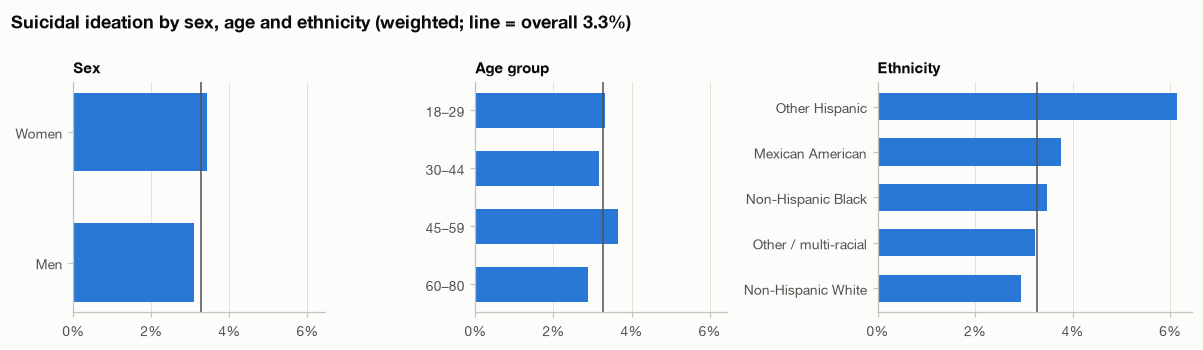

weighted_si_%
group     level                              
Sex       Men                            3.08
          Women                          3.44
Age group 18–29                          3.31
          30–44                          3.18
          45–59                          3.66
          60–80                          2.89
Ethnicity Mexican American               3.77
          Non-Hispanic Black             3.47
          Non-Hispanic White             2.93
          Other / multi-racial           3.24
          Other Hispanic                 6.15

In [5]:
ETHNICITY = {1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
             4: "Non-Hispanic Black", 5: "Other / multi-racial"}
groups = {
    "Sex": df["sex"].map({1: "Men", 2: "Women"}),
    "Age group": pd.cut(df["age"], [17, 29, 44, 59, 80], labels=["18–29", "30–44", "45–59", "60–80"]),
    "Ethnicity": df["ethnicity"].map(ETHNICITY),
}
overall = np.average(df.si, weights=df.weight_mec) * 100
tables = {name: weighted_prevalence(df, g) for name, g in groups.items()}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharex=True,
                         gridspec_kw={"width_ratios": [1, 1, 1.25]})
for ax, (name, prev) in zip(axes, tables.items()):
    prev = prev.iloc[::-1] if name == "Age group" else prev.sort_values()
    ax.barh(prev.index.astype(str), prev.values, height=0.6, color=BLUE)
    ax.axvline(overall, color=INK_2, linewidth=1)
    ax.set_title(name, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
fig.suptitle(f"Suicidal ideation by sex, age and ethnicity (weighted; line = overall {overall:.1f}%)",
             x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "03_si_by_subgroup")
plt.show()

pd.concat(tables, names=["group", "level"]).rename("weighted_si_%").to_frame()

## 5. Which routinely recorded factors go with suicidal ideation?

Crude risk ratio = prevalence among adults **with** the factor / prevalence among adults
**without** it, with a 95% CI (log method). A ratio of 2 means twice as common.
This is a first look at the signal H1 tests; the model will adjust for overlap between
factors (for example, mental-health visits and antidepressants).

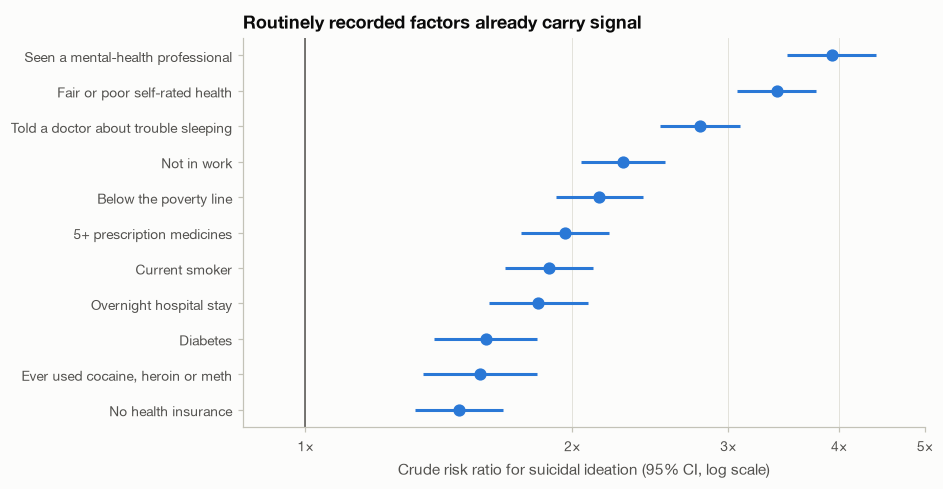

,n_with_factor,si_%_with,si_%_without,risk_ratio,ci_low,ci_high
Seen a mental-health professional,2941,11.93,3.04,3.92,3.50,4.40
Fair or poor self-rated health,8479,8.20,2.41,3.40,3.07,3.77
Told a doctor about trouble sleeping,9016,7.26,2.61,2.79,2.51,3.09
Not in work,16146,5.48,2.40,2.28,2.05,2.55
Below the poverty line,7231,6.40,2.98,2.15,1.92,2.40
5+ prescription medicines,6159,6.35,3.24,1.96,1.75,2.20
Current smoker,7038,5.98,3.18,1.88,1.68,2.11
Overnight hospital stay,4301,6.28,3.43,1.83,1.61,2.08
Diabetes,4475,5.61,3.51,1.60,1.40,1.83
"Ever used cocaine, heroin or meth",4080,5.47,3.47,1.57,1.36,1.83


In [6]:
def known(condition: pd.Series, source: pd.Series) -> pd.Series:
    """Boolean indicator that stays missing where the source variable is missing."""
    return condition.astype("boolean").mask(source.isna())


current_smoker = df["smoking_now"].isin([1, 2]).astype("boolean").mask(df["smoked_100_cigarettes"].isna())
factors = {
    "Seen a mental-health professional": known(df.mental_health_visit == 1, df.mental_health_visit),
    "Fair or poor self-rated health": known(df.self_rated_health.isin([4, 5]), df.self_rated_health),
    "Told a doctor about trouble sleeping": known(df.sleep_trouble == 1, df.sleep_trouble),
    "Ever used cocaine, heroin or meth": known(df.ever_hard_drugs == 1, df.ever_hard_drugs),
    "Not in work": known(df.work_status.isin([3, 4]), df.work_status),
    "Below the poverty line": known(df.income_poverty_ratio < 1, df.income_poverty_ratio),
    "Current smoker": current_smoker,
    "Overnight hospital stay": known(df.hospital_stay == 1, df.hospital_stay),
    "5+ prescription medicines": known(df.rx_count >= 5, df.rx_count),
    "No health insurance": known(df.insured == 0, df.insured),
    "Diabetes": known(df.diabetes == 1, df.diabetes),
}


def risk_ratio(exposed: pd.Series, outcome: pd.Series) -> dict:
    ok = exposed.notna()
    e, y = exposed[ok].astype(bool), outcome[ok]
    n1, n0 = e.sum(), (~e).sum()
    p1, p0 = y[e].mean(), y[~e].mean()
    rr = p1 / p0
    se = np.sqrt((1 - p1) / (n1 * p1) + (1 - p0) / (n0 * p0))
    return {"n_with_factor": n1, "si_%_with": 100 * p1, "si_%_without": 100 * p0,
            "risk_ratio": rr, "ci_low": rr * np.exp(-1.96 * se), "ci_high": rr * np.exp(1.96 * se)}


rr = pd.DataFrame({name: risk_ratio(s, df.si) for name, s in factors.items()}).T
rr = rr.astype(float).sort_values("risk_ratio")

fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(rr))
ax.hlines(y, rr.ci_low, rr.ci_high, color=BLUE, linewidth=2)
ax.plot(rr.risk_ratio, y, "o", color=BLUE, markersize=7)
ax.axvline(1, color=INK_2, linewidth=1)
ax.set_xscale("log")
ax.set_xlim(0.85, 5)
ax.set_xticks([1, 2, 3, 4, 5])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
ax.minorticks_off()
ax.set_yticks(y, rr.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Crude risk ratio for suicidal ideation (95% CI, log scale)")
ax.set_title("Routinely recorded factors already carry signal")
save(fig, "04_risk_ratios")
plt.show()

rr.iloc[::-1].astype({"n_with_factor": int})

## 6. Where are data missing?

Share of missing values per variable and cycle (variables with any missing values above 1%).
Most of it is by design — questions asked only from age 20, or only to people who
answered a previous question in a certain way — see `docs/codebook.md`.

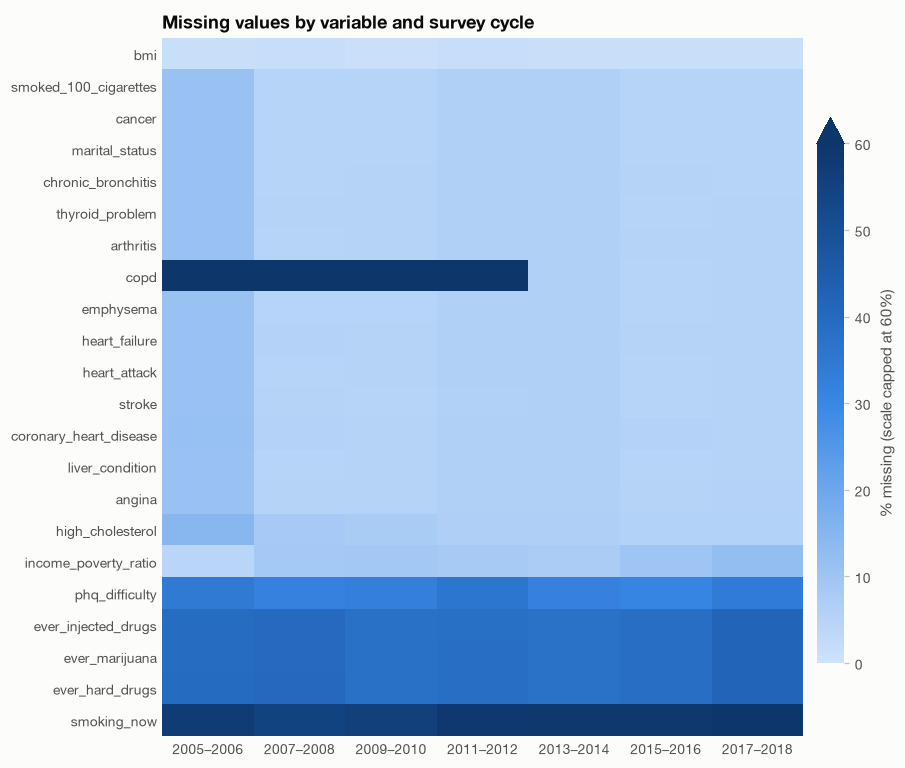

,2005-2006,2007-2008,2009-2010,2011-2012,2013-2014,2015-2016,2017-2018
variable,,,,,,,
bmi,1.0,1.2,0.9,1.3,1.0,1.0,1.1
smoked_100_cigarettes,10.8,4.8,4.8,5.9,6.0,4.9,4.8
cancer,10.8,4.9,4.9,5.9,5.9,4.9,4.8
marital_status,10.8,4.8,4.9,5.9,6.0,4.8,4.9
chronic_bronchitis,11.0,4.9,5.0,5.9,6.1,5.1,4.9
thyroid_problem,10.9,5.0,5.0,6.1,6.1,4.9,5.0
arthritis,10.9,4.9,5.0,5.9,6.1,5.0,5.0
copd,100.0,100.0,100.0,100.0,6.0,4.9,5.0
emphysema,10.8,4.9,4.8,5.9,6.0,4.9,5.0


In [7]:
miss = pd.read_csv(REPORT_TABLES / "missingness_by_cycle.csv", index_col="variable")
miss = miss.drop(columns="all")
miss = miss[miss.max(axis=1) > 1].sort_values("2017-2018")

fig, ax = plt.subplots(figsize=(8, 0.32 * len(miss) + 1.2))
im = ax.imshow(miss.values, cmap=SEQUENTIAL, vmin=0, vmax=60, aspect="auto")
ax.set_xticks(range(miss.shape[1]), [c.replace("-", "–") for c in miss.columns])
ax.set_yticks(range(len(miss)), miss.index)
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=ax, extend="max", fraction=0.04, pad=0.02)
cbar.set_label("% missing (scale capped at 60%)")
cbar.outline.set_visible(False)
ax.set_title("Missing values by variable and survey cycle")
save(fig, "05_missingness")
plt.show()

miss

## Takeaways

- **The outcome is rare:** 3.8% of the cohort (1,366 of 36,259), 3.3% weighted. The weighted figure is lower because NHANES oversamples groups with a higher prevalence. Model metrics use the unweighted sample, so the PR-AUC baseline in H1 is the unweighted test prevalence (3.75%).
- **Stable from 2005 to 2018** (2.9–3.4% weighted), which supports training on older cycles and testing on newer ones (H4). 2021–23 is higher (5.3%). That cycle followed the pandemic interruption of NHANES and is a descriptive check only, not modelled.
- **42% of cases score below 10 on the other eight PHQ items** (579 of 1,366; 43.7% weighted). With the full PHQ-9 screen of the research question, 35% still screen negative (472 of 1,366; 36.7% weighted), because item 9 itself adds to the score. These are the adults the main research question targets. Most of the 579 are not symptom-free: 512 of the 579 score between 3 and 9.
- **Subgroups differ only a little,** except *Other Hispanic* adults (6.2%). Ideation is slightly more common in women (3.4% vs 3.1%). It peaks at ages 45–59 (3.7%) and is lowest at 60–80 (2.9%). The fairness analysis (H4) needs per-group confidence intervals, because the smaller groups are noisy.
- **Every routine factor tested goes with suicidal ideation** (crude risk ratios 1.5–3.9, all 95% CIs above 1). The strongest are a mental-health visit (3.9×), fair or poor self-rated health (3.4×) and sleep trouble (2.8×). These are crude: "not in work" includes retirees, and the factors overlap. The models in step 4 account for both.
- **Missing data are mostly by design:**
  - Questions asked from age 20 are about 5% missing (11% in 2005–06, which oversampled adolescents).
  - Drug use is about 38% missing (asked only at ages 20–59).
  - `smoking_now` and `phq_difficulty` follow skip patterns.
  - COPD exists only from 2013, so step 2 uses emphysema and chronic bronchitis instead.
  - Income is the only variable with real non-response (4–12%, rising), so it needs a missing-indicator in step 2.

**Next:** step 2, feature engineering (medication classes from the prescriptions table, multimorbidity count, missing-indicators).
